# 01 - Loading and Inspecting Data

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_a_foundations/01_loading_and_inspecting_data.ipynb)

**Part A - Foundations - Petrophys Curriculum**

In lesson 00 we met the sample data at arm's length. Now we open up the **data model**
itself. Everything in *petrophys* revolves around two objects:

- a **`Well`** - one borehole, its header, its depth reference, and a collection of curves;
- a **`Curve`** - one logged measurement (GR, RHOB, ...) with its data array, unit, and
  statistics.

Master these two objects and the rest of the library becomes easy to read.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

- Load a well with `pp.read` - the front door for LAS, DLIS, CSV, TSV and Excel files.
- Navigate the **`Well`** object: `name`, `header`, `info()`, `n_curves`,
  `n_samples`, `depth`/`depth_unit`, `top`/`bottom`/`step`.
- Navigate the **`Curve`** object: `.data`, `.unit`, `.mnemonic`, statistics
  (`mean/min/max/std/median/percentile`), `valid_count()`/`null_count()`, `.describe()`.
- Look curves up safely with `has_curve` / `has_curves` / `get`.
- Take a curve inventory with `describe()`, move to tabular form with `to_dataframe()`
  and subset with `depth_slice()`.
- Plot existing measurements with `pp.plot` without running an interpretation.
- Contrast the curve inventory of a clastic well (30/6-5) and a carbonate well (`HW-3`).

## Why this matters

A log file is only useful once you know **what is in it and how trustworthy it is**. Before
any petrophysical equation runs, an interpreter asks: *which curves do I have? what units?
how many samples are null? what is the depth coverage?* The `Well`/`Curve` API answers all
of these in a few lines - and getting them wrong (mixing units, ignoring nulls) silently
corrupts every downstream calculation.

### Prerequisites

This lesson assumes **lesson 00** (orientation and setup) - specifically that you can
list samples with `pp.list_samples(...)` and resolve their paths with `pp.sample(...)`.

In [2]:
import pandas as pd
import petrophys as pp

## 1. Read a file with the public API

`pp.read` returns a `Well` from LAS, DLIS, CSV, TSV or Excel, choosing the reader from the file extension. LAS carries curve/header metadata; tabular logs need an explicit depth unit. DLIS requires the optional `dlis` dependency. Unknown reader options raise rather than being silently ignored. The format readers in `petrophys.io` (`read_las`, `read_dlis`, `read_csv`) are also available; for a LAS file `read_las` returns the same `Well`, with the same curve names and units.

In [3]:
w = pp.read(pp.sample("30_6-5"))
w

Well(30/6-5, curves=20, samples=22176)

### A portable CSV/TSV example

A CSV file stores neither the depth unit nor the curve units, so declare the depth unit
when you read one (`depth_unit="m"` or `"ft"`) and, if the depth column has another
name, `depth_column=`. The cell below writes the Brent Group interval of 30/6-5 to a
temporary CSV with `Well.to_csv` and reads it back; it is an excerpt of the LAS, not an
independent well. `to_csv(path, sep="\t")` writes TSV the same way. Multiwell log
tables use `petrophys.io.read_csv_wells`.

For optional external geology and Excel sheet/column mapping, continue to [Your own data](../../docs/own_data.md). Neither geology file is a prerequisite for loading, plotting, or the normal interpretation workflow.

In [4]:
import tempfile

csv_path = tempfile.mkdtemp() + "/30_6-5_brent.csv"
w.depth_slice(2841, 2958).to_csv(csv_path)
pp.read(csv_path, depth_unit="m")

Well(30_6-5_brent, curves=20, samples=768)

## 2. The `Well` object

A `Well` bundles three things: **identity** (header), a **depth reference**, and a
**collection of curves**. Each is an attribute.

In [5]:
w.header, w.n_curves, w.n_samples

(WellHeader(name=30/6-5, uwi=30/6-5), 20, 22176)

In [6]:
w.depth_unit, w.top, w.bottom, w.step

('m', 176.60999, 3556.08032, 0.15235000000029686)

Key points:

- `w.header` is a small **`WellHeader`** object; its `.field` and `.uwi` attributes are the
  most commonly used identifiers.
- `w.depth` is a NumPy array of length `n_samples`. Every curve's data array is **aligned to
  this same depth axis**, so `curve.data[i]` corresponds to `w.depth[i]`.
- `step` is the (nominal) sample spacing, here 0.1524 m (half a foot). A near-constant step
  is typical of wireline data; it lets us convert sample counts into thicknesses.

In [7]:
w.curves

['LITHOLOGY_GEOLINK',
 'CALI',
 'DRHO',
 'NPHI',
 'RHOB',
 'PEF',
 'GR',
 'DTC',
 'DTE',
 'RDEP',
 'SP',
 'RSHA',
 'RMED',
 'BS',
 'PHIC',
 'GDEN',
 'KH_CORE',
 'KV_CORE',
 'SWC',
 'SOC']

In [8]:
w.has_curve("GR"), w.has_curve("SONIC"), w.has_curves(["GR", "RHOB"]), w.has_curves(["GR", "FOO"])

(True, False, True, False)

> **Habit:** always guard with `has_curve` / `has_curves` before calling `get`. Real-world
> LAS files are inconsistent about which curves they carry, and a missing curve should be a
> handled case, not a crash.

## 3. The `Curve` object

`w.get(mnemonic)` (or `w[mnemonic]`) returns a **`Curve`**. A curve wraps its data array
plus metadata and a set of statistics helpers.

In [9]:
gr = w.get("GR")
gr, gr.unit, gr.data[:5]

(Curve(GR, unit=gAPI, samples=22176),
 'gAPI',
 array([ 9.56288,  9.531  ,  9.53956, 11.90846, 12.57125]))

### Curve statistics

Curves expose convenience statistics that respect nulls (NaNs):

- point stats: `.mean()`, `.min()`, `.max()`, `.std()`, `.median()`, `.percentile(p)`
- data-quality counts: `.valid_count()` and `.null_count()` (these are **methods** - call
  them with `()`)
- a one-shot summary: `.describe()` returns a dict of count, nulls, min/max, mean, std,
  median, and the p25/p75 quartiles.

The GR minimum is negative (-12.6 API), which no gamma-ray tool can measure; lesson 02
removes such values with value-range QC.

In [10]:
gr.describe()

{'count': 22176,
 'null_count': 0,
 'min': -12.59262,
 'max': 238.0,
 'mean': 59.768001958423525,
 'std': 29.75386649831589,
 'median': 53.299405,
 'p25': 38.781935000000004,
 'p75': 72.44039}

In [11]:
gr.percentile(10), gr.percentile(90), gr.valid_count()

(30.038114999999998, 102.75, 22176)

### Nulls are everywhere - and they matter

Real logs are full of gaps: a tool may not run over the whole hole, core plugs exist only
at sparse depths, and so on. `w.describe()` summarizes the whole well, including every
curve's unit and share of valid samples; below it is turned into a table sorted by
coverage. Watch how the core curves (`PHIC`, `KH_CORE`, `SWC`, ...) are almost entirely
null - they exist only where a plug was measured - while most wireline logs are
near-complete. Not all of them, though: `NPHI`/`DRHO` cover only ~79% of the hole
and `PEF` a mere ~12%.

In [12]:
pd.DataFrame(w.describe()["curves"]).sort_values("valid_fraction", ascending=False)

,mnemonic,unit,description,valid_fraction
9,RDEP,ohm.m,RDEP,1.000
10,SP,mV,SP,1.000
6,GR,gAPI,GR,1.000
4,RHOB,g/cm3,RHOB,1.000
13,BS,in,BIT SIZE,1.000
12,RMED,ohm.m,RMED,1.000
8,DTE,us/ft,DTE,0.996
1,CALI,in,CALI,0.996
11,RSHA,ohm.m,RSHA,0.996
7,DTC,us/ft,DTC,0.996


The `valid_fraction` column is a fast **coverage QC**: most wireline curves near 1, core
curves near 0 - but note `NPHI`/`DRHO` at 0.786 and `PEF` at only 0.116. Coverage
itself is a QC finding: it tells you where a curve simply cannot support an answer. Any downstream statistic silently drops nulls - so a mean over a curve that is 99%
null (like `SWC`) is really the mean of a handful of core plugs, not a log average. Knowing
this prevents badly wrong conclusions later.

## 4. Tabular view: `to_dataframe()`

For pandas-style work, `w.to_dataframe()` returns a `DataFrame` with a `DEPTH` column plus
one column per curve, all aligned on the same rows. The first rows sit at the top of the
log, where the neutron was not run (`NaN`) and the deep resistivity reads at the
2000 ohm.m top of its range.

In [13]:
df = w.to_dataframe()
df[["DEPTH", "GR", "RHOB", "NPHI", "RDEP"]].head()

,DEPTH,GR,RHOB,NPHI,RDEP
0,176.60999,9.56288,1.0,NaN,1999.98706
1,176.76239,9.53100,1.0,NaN,1999.99500
2,176.91478,9.53956,1.0,NaN,2000.00403
3,177.06718,11.90846,1.0,NaN,2000.01184
4,177.21959,12.57125,1.0,NaN,1999.86816


## 5. Subsetting depth: `depth_slice()`

`w.depth_slice(top, bottom)` returns a **new `Well`** covering only the requested interval.
This is how you zoom into a reservoir zone without disturbing the full well. The returned
object is a full `Well`, so all the same attributes and methods apply. The mean GR of
2500-2600 m, a shale-dominated interval above the reservoir, is about twice the
whole-well mean.

In [14]:
zone = w.depth_slice(2500, 2600)
zone, zone.get("GR").mean(), w.get("GR").mean()

(Well(30/6-5, curves=20, samples=656), 128.35061205792684, 59.768001958423525)

## 6. Plot existing measurements

The adaptive viewer chooses tracks from available curves. It does not run interpretation or create a missing SW curve. Recognized core percentages are normalized on a display copy, and every inferred conversion is recorded in `viewer.warnings`: the two diagnostics are the 30/6-5 core saturations `SWC` and `SOC`, which hold percentages despite a `frac` label (see lesson 00 and lesson 02). The source well stays unchanged.

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:838: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:838: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


["SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.",
 "SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units."]

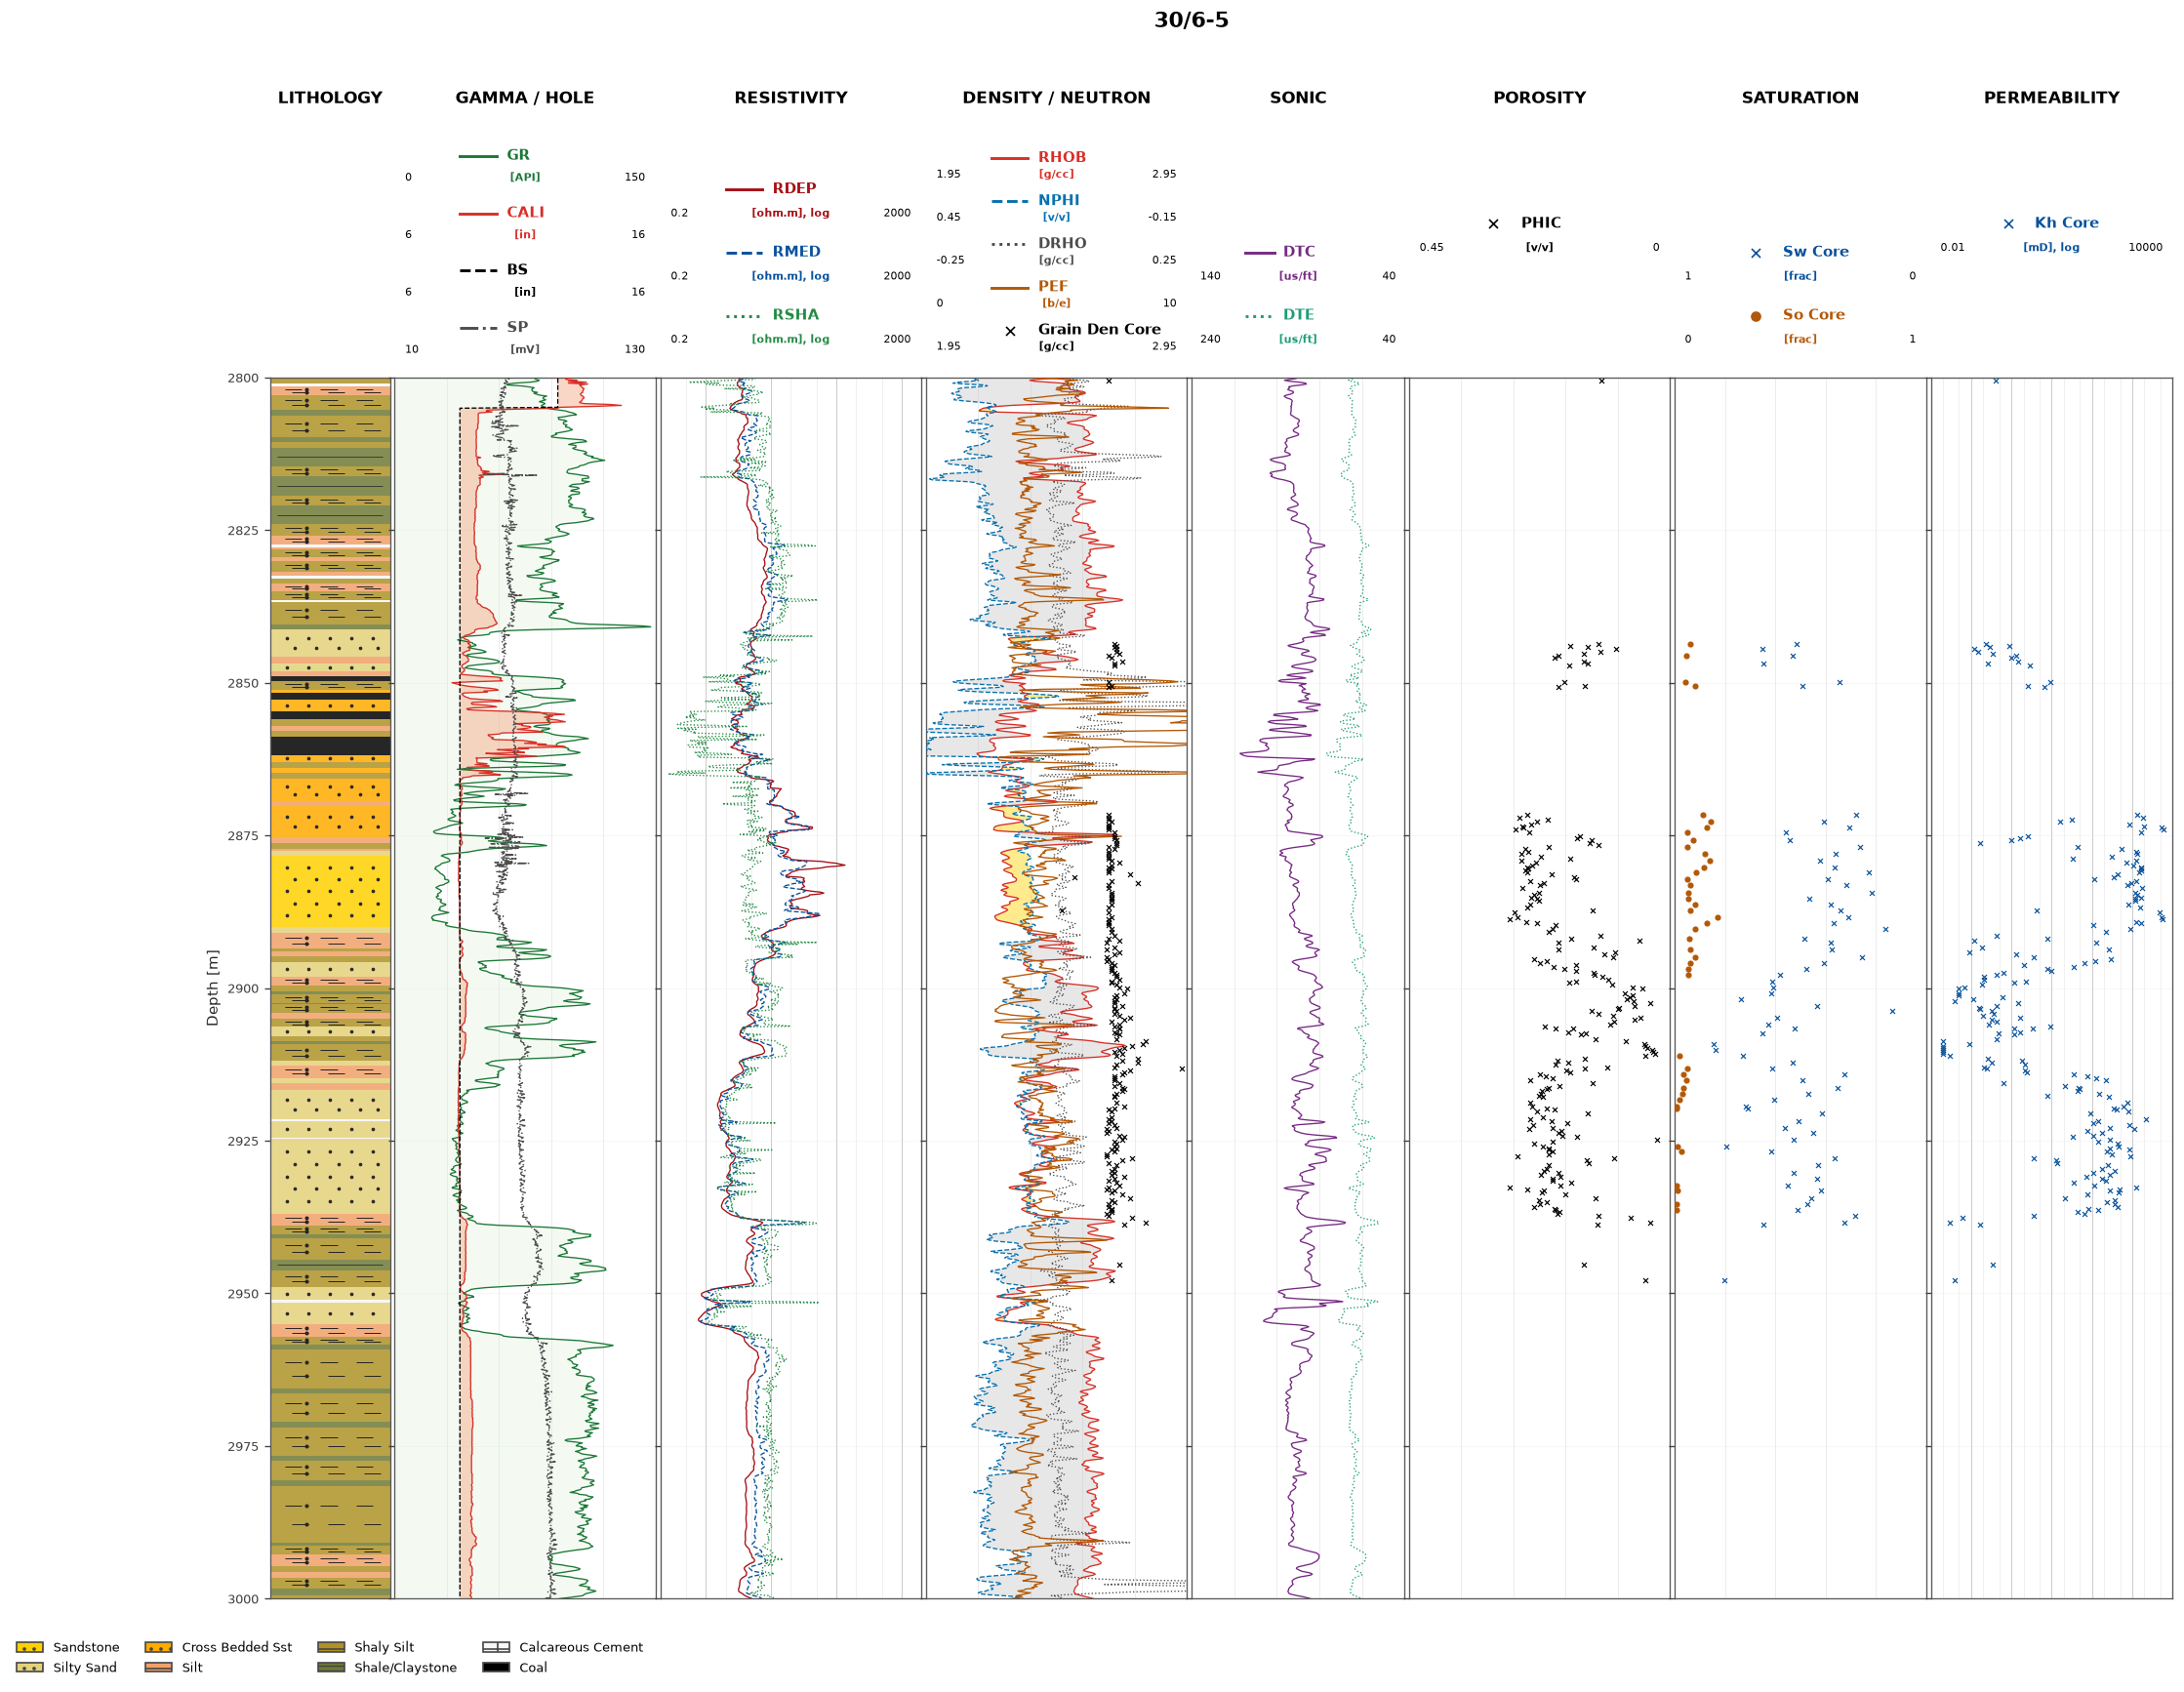

In [15]:
viewer = pp.plot(w, top=2800, bottom=3000)
viewer.warnings

## 7. Contrasting curve sets: clastic vs carbonate

Different tools were run on the two datasets, so their curve inventories differ. Let us load
the carbonate well `HW-3` and list the curves it shares with the clastic `30_6-5` and the
curves only it carries.

In [16]:
wc = pp.read(pp.sample("HW-3"))
sorted(set(w.curves) & set(wc.curves)), sorted(set(wc.curves) - set(w.curves))

(['GR', 'NPHI', 'RHOB'], ['DT', 'PERM_CC', 'PHIE_CC', 'RT', 'SW_INPUT'])

What the comparison tells us:

- **Shared core logs** - `GR`, `RHOB`, `NPHI` - are the common denominator; most workflows
  can run on either well.
- **30/6-5 is richer**: multiple resistivities (`RDEP`/`RMED`/`RSHA`), sonic (`DTC`/`DTE`),
  `PEF`, `CALI`/`BS`, plus core `PHIC`/`KH_CORE`/`KV_CORE`.
- **`HW-3` uses different names for the same idea**: sonic is `DT` (vs `DTC`), true
  resistivity is `RT` (vs `RDEP`). Instead of core measurements it carries the
  core-corrected log curves `PHIE_CC`/`PERM_CC` and the source saturation `SW_INPUT`.
- The units differ too: the HW-3 inventory below records its neutron as `ft3/ft3`
  where 30/6-5 records `m3/m3` (the same fraction), COSTA depths are in **feet**,
  GeoLink depths in **metres**, and the `HW-3` file covers only the Kharaib-2 reservoir
  interval, not the whole well.

Those naming and unit differences are precisely the problem that **curve standardization**
solves - the subject of lesson 02.

In [17]:
pd.DataFrame(wc.describe()["curves"])

,mnemonic,unit,description,valid_fraction
0,GR,gAPI,GR,1.000
1,RHOB,g/cm3,RHOB,1.000
2,NPHI,ft3/ft3,NPHI,1.000
3,DT,us/ft,DT,0.826
4,PHIE_CC,ft3/ft3,Core corrected porosity input,0.814
5,RT,ohm.m,RT,1.000
6,SW_INPUT,v/v,Source water saturation input,0.745
7,PERM_CC,mD,Core corrected permeability input,0.824


## Pitfalls and parameter choices

- **`get`, not `get_curve`.** The accessor is `w.get(mnemonic)`, or `w[mnemonic]`.
- **`valid_count` / `null_count` are methods** - remember the `()`. Forgetting it returns a
  bound method, not a number.
- **Statistics drop nulls.** A `mean()` over a mostly-null core curve reflects only the few
  measured samples. Always sanity-check `valid_fraction` before trusting a summary statistic.
- **Curves are aligned to `w.depth`.** Never assume two wells share an index - slice and
  compare on depth, not on sample number.
- **Same physics, different names.** `DTC` vs `DT`, `RDEP` vs `RT` - do not hard-code
  mnemonics across a multi-well project; standardize first (lesson 02).

## Recap

- `pp.read` returns a **`Well`** from LAS, DLIS, CSV, TSV or Excel. A `Well` has `name`,
  `header`, `n_curves`, `n_samples`, `depth`/`depth_unit`, `top`/`bottom`/`step`;
  `info()` describes them and `describe()` returns them with a per-curve inventory.
- `w.get(mnemonic)` returns a **`Curve`** with `.data`, `.unit`, `.mnemonic`, statistics
  (`mean/min/max/std/median/percentile`), `valid_count()`/`null_count()`, and `.describe()`.
- Guard lookups with `has_curve`/`has_curves`; export with `to_dataframe()` and
  `to_csv()`; zoom with `depth_slice()`; view measurements with `pp.plot`.
- Clastic (30/6-5) and carbonate (`HW-3`) wells share core logs but differ in extra
  curves, mnemonics, and units - motivating the QA/QC work ahead.

## Try it yourself

> **Exercise 1.** Build the coverage table of section 3 for `HW-3`, sorted ascending by
> `valid_fraction`. Which curves are sparse there?
>
> **Exercise 2.** Slice `30_6-5` to the interval 2600-2700 m and compute the RHOB and NPHI
> means for that zone. Compare with the whole-well means. Is this interval more or less
> porous than average? (Higher NPHI and lower RHOB generally mean more porosity.)
>
> **Exercise 3.** For `HW-3`, plot `PHIE_CC` (core-corrected porosity) and `PERM_CC`
> (core-corrected permeability) with `pp.plot(wc, curves=["PHIE_CC", "PERM_CC"])`.
> Where in the Kharaib-2 interval is the best reservoir quality?

## What's next

Continue with **`02_qaqc_and_standardization.ipynb`**. With a well and its curves in hand,
we condition the data: standardize mnemonics and units, flag bad-hole intervals with
the caliper, apply value-range QC, and normalize a curve across the COSTA field so multi-well
comparisons become meaningful.